<a href="https://colab.research.google.com/github/isaagianni/TP_Final_Vision/blob/main/notebooks/01_exploracion_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploración del Dataset AI Cook

Trabajo Práctico Final – Visión Artificial

Análisis exploratorio del dataset utilizado para la detección de alimentos en heladeras y la posterior comparación de modelos YOLO y DETR.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving aicook.v1i.yolov8.zip to aicook.v1i.yolov8.zip


In [2]:
from pathlib import Path
from zipfile import ZipFile

zip_name = next(iter(uploaded))
dataset_dir = Path("/content/ai_cook")

with ZipFile(zip_name, "r") as zip_file:
    zip_file.extractall(dataset_dir)

print("Dataset descomprimido correctamente")
print("\nArchivos y carpetas:")
for item in sorted(dataset_dir.iterdir()):
    print(item.name)


Dataset descomprimido correctamente

Archivos y carpetas:
README.dataset.txt
README.roboflow.txt
data.yaml
test
train
valid


In [3]:

import yaml

# Leer la configuración del dataset
with open(dataset_dir / "data.yaml", "r") as file:
    data = yaml.safe_load(file)

# Mostrar las clases
print("Cantidad de clases:", data["nc"])
print("\nClases de alimentos:")
for name in data["names"]:
    print(name)

# Contar imágenes y anotaciones
print("\nDistribución del dataset:")

for split in ["train", "valid", "test"]:
    image_dir = dataset_dir / split / "images"
    label_dir = dataset_dir / split / "labels"

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    print(f"{split}: {len(images)} imágenes, {len(labels)} anotaciones")


Cantidad de clases: 30

Clases de alimentos:
apple
banana
beef
blueberries
bread
butter
carrot
cheese
chicken
chicken_breast
chocolate
corn
eggs
flour
goat_cheese
green_beans
ground_beef
ham
heavy_cream
lime
milk
mushrooms
onion
potato
shrimp
spinach
strawberries
sugar
sweet_potato
tomato

Distribución del dataset:
train: 362 imágenes, 362 anotaciones
valid: 103 imágenes, 103 anotaciones
test: 51 imágenes, 51 anotaciones


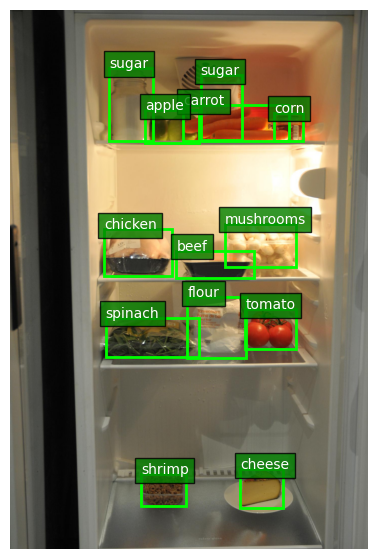

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Elegir una imagen de entrenamiento
image_dir = dataset_dir / "train" / "images"
image_path = sorted(image_dir.glob("*.jpg"))[0]

# Abrir la imagen
image = Image.open(image_path)
width, height = image.size

# Buscar su archivo de anotaciones
label_path = dataset_dir / "train" / "labels" / (image_path.stem + ".txt")

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Dibujar los bounding boxes
with open(label_path, "r") as file:
    for line in file:
        values = line.split()

        class_id = int(values[0])
        xc, yc, w, h = map(float, values[1:])

        # Convertir coordenadas normalizadas a píxeles
        x = (xc - w / 2) * width
        y = (yc - h / 2) * height
        box_width = w * width
        box_height = h * height

        # Dibujar rectángulo
        rect = patches.Rectangle(
            (x, y), box_width, box_height,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)

        # Mostrar nombre del alimento
        ax.text(
            x, y, data["names"][class_id],
            color="white",
            bbox={"facecolor": "green", "alpha": 0.8}
        )

ax.axis("off")
plt.show()


# Analizar la distribución de clases
Necesitamos saber cuántos ejemplos tenemos de cada alimento.

In [5]:
from collections import Counter
import pandas as pd

class_names = data["names"]

# Contar objetos de cada clase en cada conjunto
counts = {}

for split in ["train", "valid", "test"]:
    counter = Counter()
    label_dir = dataset_dir / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        with open(label_path, "r") as file:
            for line in file:
                if line.strip():
                    class_id = int(line.split()[0])
                    counter[class_id] += 1

    counts[split] = counter

# Crear tabla de distribución de clases
rows = []

for class_id, name in enumerate(class_names):
    train_count = counts["train"][class_id]
    valid_count = counts["valid"][class_id]
    test_count = counts["test"][class_id]

    rows.append({
        "Clase": name,
        "Train": train_count,
        "Valid": valid_count,
        "Test": test_count,
        "Total": train_count + valid_count + test_count
    })

df_classes = pd.DataFrame(rows)
df_classes = df_classes.sort_values(
    "Total", ascending=False
)

display(df_classes)

print("Total de objetos anotados:", df_classes["Total"].sum())


,Clase,Train,Valid,Test,Total
27,sugar,229,78,12,319
29,tomato,236,59,12,307
26,strawberries,230,51,24,305
13,flour,197,58,46,301
23,potato,213,64,23,300
7,cheese,221,49,30,300
20,milk,168,48,44,260
15,green_beans,169,47,25,241
24,shrimp,182,42,15,239
11,corn,171,48,18,237


Total de objetos anotados: 6396


Observación: La clase sugar tiene casi cuatro veces más ejemplos que ham. Entonces hay un desbalance de clases, y puede influir en el entrenamiento, porque algunas clases tienen muchos más ejemplos que otras.  
Hay dos clases que no aparecen en el test
- goat_cheese: 106 objetos en total, pero 0 en test.
- ham: 81 objetos en total, pero 0 en test.  
Entonces cuando evaluemos los modelos sobre el test de AI Cook, no podremos medir adecuadamente su capacidad para detectar esas dos clases, porque no hay ejemplos reales de ellas en ese conjunto.
Por eso, antes de entrenar, hay que revisar la calidad de la división original y los posibles duplicados.

# Gráfico de distribución de clases

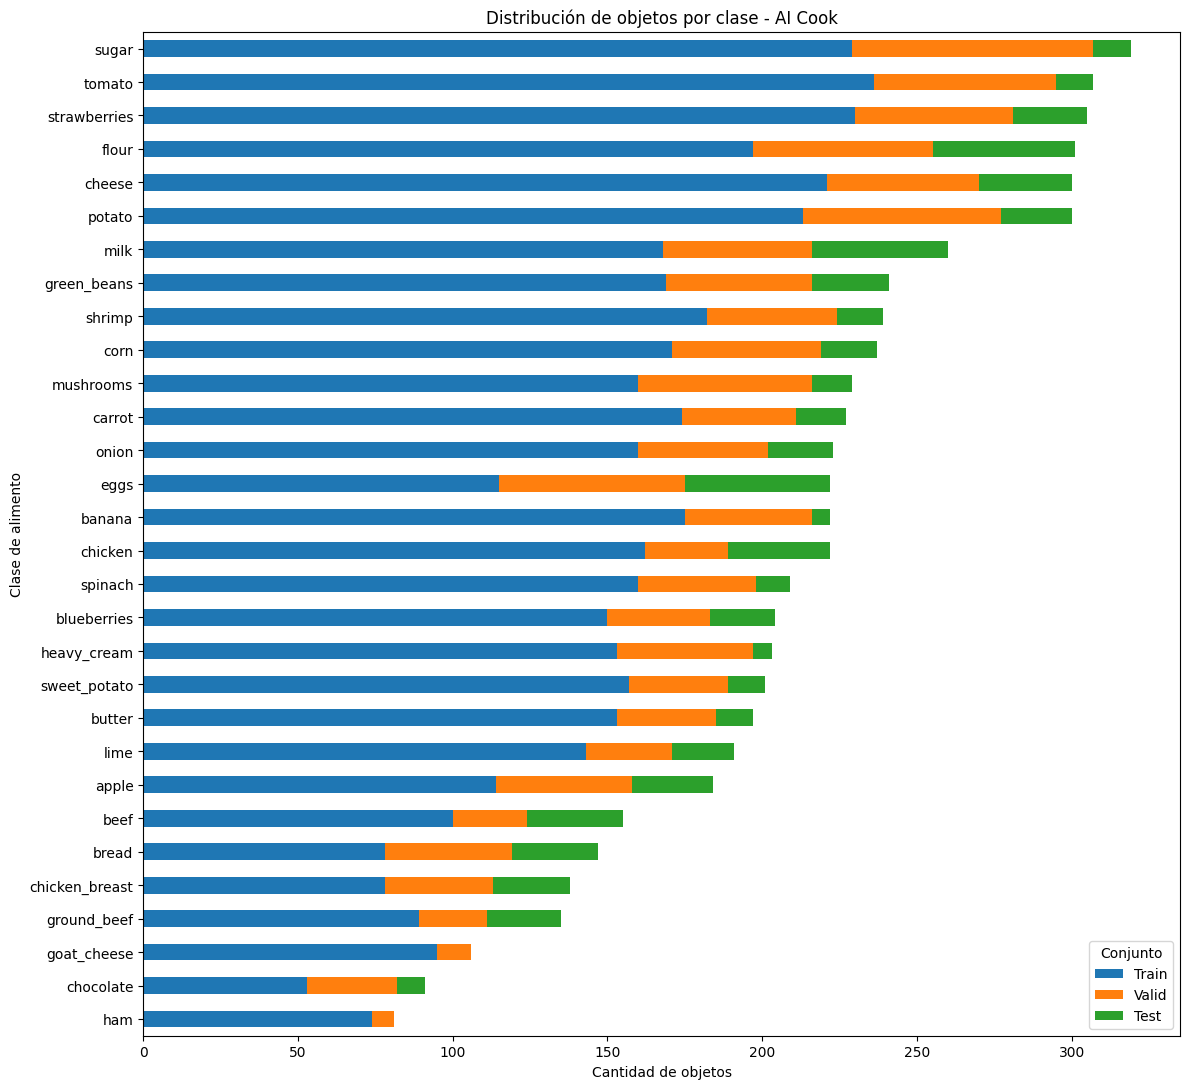

In [6]:
import matplotlib.pyplot as plt

# Ordenar las clases por cantidad total de objetos
df_plot = df_classes.sort_values("Total", ascending=True)

# Graficar la cantidad de objetos en cada conjunto
ax = df_plot.set_index("Clase")[["Train", "Valid", "Test"]].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 11)
)

plt.title("Distribución de objetos por clase - AI Cook")
plt.xlabel("Cantidad de objetos")
plt.ylabel("Clase de alimento")
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()


El dataset está desbalanceado: algunas clases, como sugar, tomato y strawberries, tienen más ejemplos que otras, como ham y chocolate.

Hay clases sin ejemplos en test: ham y goat_cheese no aparecen en el conjunto de prueba, por lo que no podremos evaluar su detección mediante ejemplos positivos en ese conjunto.

La distribución cambia según la clase: no todas tienen la misma proporción de objetos en train, validación y test.

# Analizar el tamaño de los objetos

Cantidad de objetos: 4559
Área mediana: 1.22%
Área mínima: 0.11%
Área máxima: 5.63%


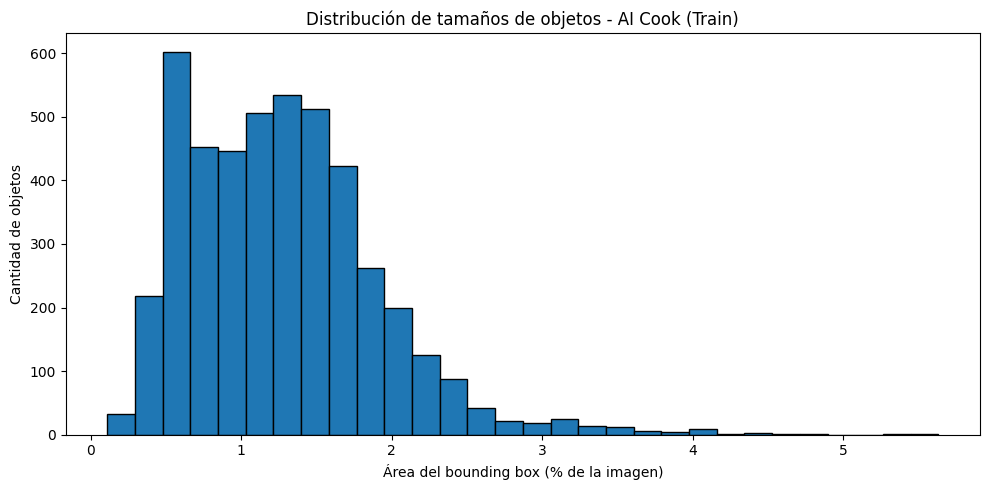

In [7]:

import numpy as np
import matplotlib.pyplot as plt

areas = []

label_dir = dataset_dir / "train" / "labels"

for label_path in label_dir.glob("*.txt"):
    with open(label_path, "r") as file:
        for line in file:
            values = line.split()

            if not values:
                continue

            # Ancho y alto normalizados del bounding box
            width = float(values[3])
            height = float(values[4])

            # Porcentaje de la imagen ocupado por el objeto
            area = width * height * 100
            areas.append(area)

print("Cantidad de objetos:", len(areas))
print(f"Área mediana: {np.median(areas):.2f}%")
print(f"Área mínima: {np.min(areas):.2f}%")
print(f"Área máxima: {np.max(areas):.2f}%")

plt.figure(figsize=(10, 5))
plt.hist(areas, bins=30, edgecolor="black")

plt.title("Distribución de tamaños de objetos - AI Cook (Train)")
plt.xlabel("Área del bounding box (% de la imagen)")
plt.ylabel("Cantidad de objetos")
plt.tight_layout()
plt.show()


# Buscar imágenes exactamente duplicadas

In [8]:

import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for split in ["train", "valid", "test"]:
    image_dir = dataset_dir / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        # Calcular una huella digital de la imagen
        image_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()

        hashes[image_hash].append((split, image_path.name))

# Buscar imágenes idénticas en conjuntos diferentes
duplicates = []

for files in hashes.values():
    splits = set(split for split, name in files)

    if len(splits) > 1:
        duplicates.append(files)

print("Grupos de imágenes duplicadas entre conjuntos:", len(duplicates))

for group in duplicates[:10]:
    print(group)


Grupos de imágenes duplicadas entre conjuntos: 0


# Buscar imágenes muy parecidas
el modelo podría obtener resultados muy buenos en el test simplemente porque ya vio escenas prácticamente iguales durante el entrenamiento.  
Buscamos imágenes visualmente similares utilizando un método llamado perceptual hashing (pHash).

Pares potencialmente similares: 7057


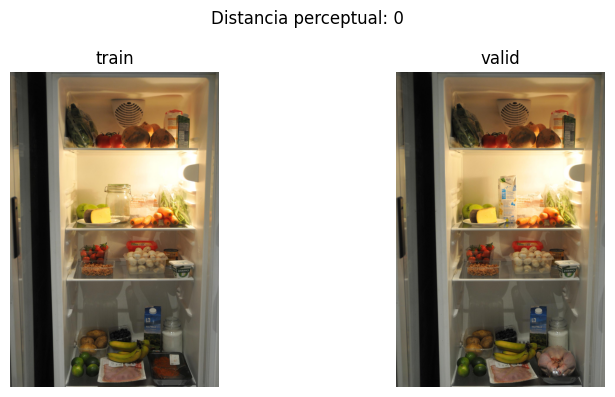

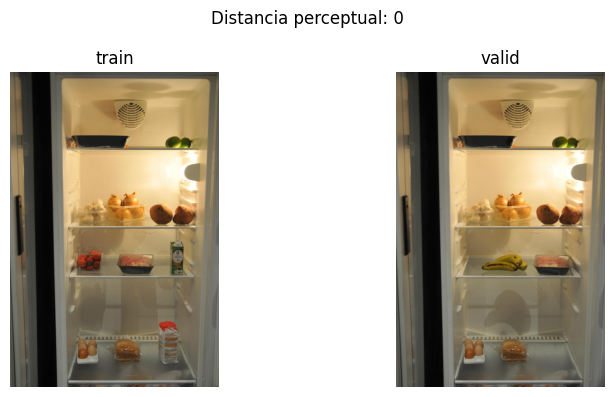

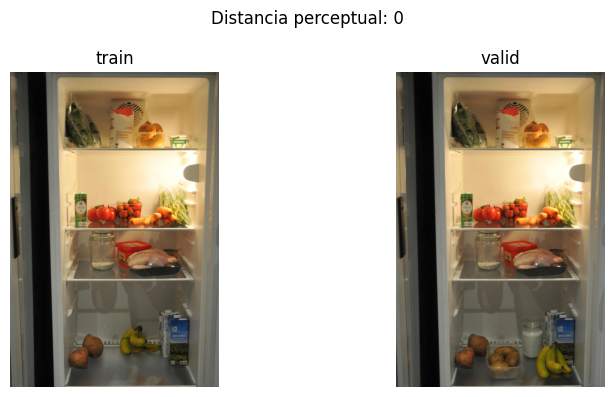

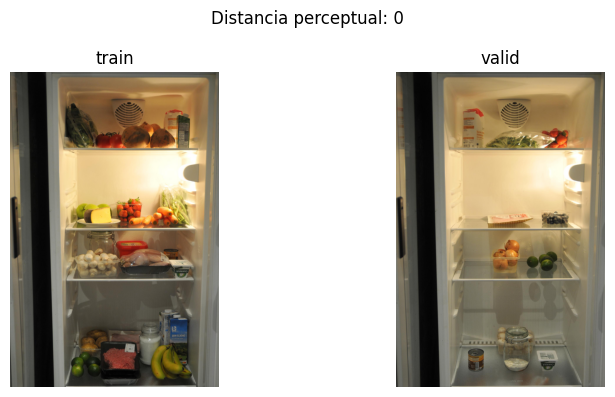

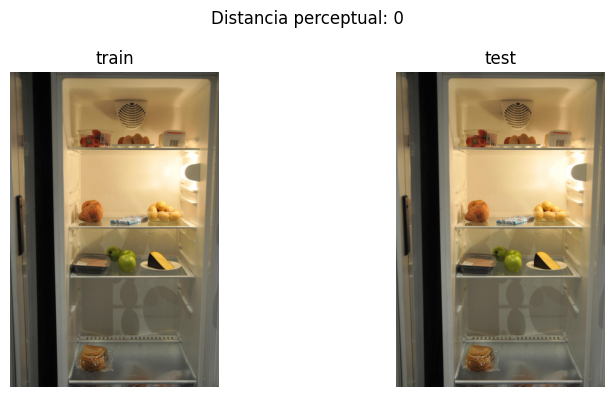

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def perceptual_hash(image_path):
    image = Image.open(image_path).convert("L")
    image = image.resize((32, 32))

    dct = cv2.dct(np.float32(image))
    values = dct[:8, :8].flatten()

    median = np.median(values[1:])
    return values > median

# Obtener imágenes y calcular sus hashes
images = []

for split in ["train", "valid", "test"]:
    folder = dataset_dir / split / "images"

    for path in folder.iterdir():
        if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            images.append((split, path, perceptual_hash(path)))

# Comparar imágenes de conjuntos diferentes
similar_pairs = []

for i in range(len(images)):
    for j in range(i + 1, len(images)):
        split1, path1, hash1 = images[i]
        split2, path2, hash2 = images[j]

        if split1 == split2:
            continue

        distance = np.count_nonzero(hash1 != hash2)

        if distance <= 8:
            similar_pairs.append((distance, path1, path2))

similar_pairs.sort(key=lambda x: x[0])

print("Pares potencialmente similares:", len(similar_pairs))

# Mostrar los 5 pares más similares
for distance, path1, path2 in similar_pairs[:5]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    axes[0].imshow(Image.open(path1))
    axes[0].set_title(path1.parent.parent.name)

    axes[1].imshow(Image.open(path2))
    axes[1].set_title(path2.parent.parent.name)

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Distancia perceptual: {distance}")
    plt.tight_layout()
    plt.show()


In [10]:

from skimage.metrics import structural_similarity as ssim
from PIL import Image
import numpy as np

def calculate_ssim(path1, path2):
    img1 = Image.open(path1).convert("RGB").resize((256, 256))
    img2 = Image.open(path2).convert("RGB").resize((256, 256))

    img1 = np.array(img1)
    img2 = np.array(img2)

    return ssim(
        img1,
        img2,
        channel_axis=2,
        data_range=255
    )

# Comparar los primeros 5 pares encontrados
for i, (distance, path1, path2) in enumerate(similar_pairs[:5]):
    score = calculate_ssim(path1, path2)

    print(f"Par {i + 1}:")
    print(f"  pHash: {distance}")
    print(f"  SSIM: {score:.4f}")
    print()


Par 1:
  pHash: 0
  SSIM: 0.9120

Par 2:
  pHash: 0
  SSIM: 0.8444

Par 3:
  pHash: 0
  SSIM: 0.9278

Par 4:
  pHash: 0
  SSIM: 0.5975

Par 5:
  pHash: 0
  SSIM: 0.9861

